# Makisushi — Notebook 2: Exploratory Data Analysis

**Dataset:** 2021-01-01 → 2026-09-08 (2,077 days) for a Japanese restaurant at
Panay Ave × EDSA, Quezon City. Sales from 2025-12-01 onward are the owner's real
records; everything before that, and all inventory/waste history, is generated by
`makisushi_datagen.py`.

**What this notebook is for.** The capstone builds a decision-support layer for
perishable raw-material inventory and food-waste reduction. Before forecasting or
optimising anything, we need to know the data holds together. So this notebook
works through four questions:

1. **Is the stitch invisible?** Real and generated sales have to look like one
   series, or every model trained on the history is learning a seam.
2. **Are sales and inventory actually connected?** This is the central claim:
   stock moves because dishes were sold, through the recipes. §3 tests it directly.
3. **Where does the money leak?** Waste, stockouts, and over-ordering — the
   problems the DSS exists to fix.
4. **What is hiding in here?** The generator ran on latent daily states that were
   deliberately stripped from the exports. §6 shows they left fingerprints — the
   confounding a naive analysis would walk straight into.

## 0. Every column in the dataset

Run this first — it stands on its own and needs nothing else in the notebook.
It reads the headers straight off the files, so it is the schema a reader will
actually find in the exports.

In [1]:
import pandas as pd
from pathlib import Path

DATA = Path("generated")          # full path if the notebook lives elsewhere

TABLES = ["sales", "inventory", "waste", "suppliers",
          "menu_items", "ingredients", "recipes", "calendar"]

for name in TABLES:
    cols = pd.read_csv(DATA / f"{name}.csv", nrows=0).columns    # header only
    print(f"{name}  ({len(cols)} columns)")
    print("   " + ", ".join(cols) + "\n")

sales  (14 columns)
   sale_id, date_id, item_id, sku, category, quantity_sold, unit_price, gross_sales, discount, net_sales, cost_of_goods, taxes, channel, is_comp

inventory  (13 columns)
   inventory_id, date_id, ingredient_id, supplier_id, opening_stock, qty_received, qty_consumed, qty_wasted, closing_stock, reorder_level, order_qty, on_order_qty, stockout_flag

waste  (13 columns)
   waste_id, date_id, ingredient_id, supplier_id, batch_id, waste_quantity, uom, waste_reason, unit_cost, waste_value_php, received_date, expiry_date, days_held

suppliers  (8 columns)
   supplier_id, supplier_name, category_served, lead_time_mean, lead_time_sd, fill_rate, min_order_qty, delivery_cadence_days

menu_items  (10 columns)
   item_id, sku, item_name, category, price, is_promo, is_comp, is_active, date_introduced, date_retired

ingredients  (12 columns)
   ingredient_id, ingredient_code, ingredient_name, category, storage_type, uom, portion_g, pack_size, shelf_life_days, is_perishable, unit_co

The same thing as a data dictionary — dtype, how much of each column is
populated, and a real value so the units are never in doubt. Also written out as
`data_dictionary.csv` for the write-up.

In [2]:
rows = []
for name in TABLES:
    df = pd.read_csv(DATA / f"{name}.csv")
    for col in df.columns:
        s = df[col]
        rows.append({
            "table": name, "column": col, "dtype": str(s.dtype),
            "non_null": f"{s.notna().mean():.0%}",
            "distinct": s.nunique(dropna=True),
            "example": s.dropna().iloc[0] if s.notna().any() else "—",
        })

data_dictionary = pd.DataFrame(rows)
data_dictionary.to_csv("data_dictionary.csv", index=False)
print(f"{len(data_dictionary)} columns across {len(TABLES)} tables "
      "→ written to data_dictionary.csv")

# flag the columns that are empty on purpose, so nobody logs them as a defect
empty = data_dictionary[data_dictionary.non_null == "0%"]
if len(empty):
    print("\nalways-empty columns — kept deliberately, not a loading error:")
    for r in empty.itertuples():
        print(f"   {r.table}.{r.column}")
    print("   cost_of_goods is empty on 100% of the owner's own rows, so gross "
          "profit\n   cannot be derived from this table; date_retired is null "
          "because nothing\n   on the menu has been withdrawn yet.")

data_dictionary

88 columns across 8 tables → written to data_dictionary.csv

always-empty columns — kept deliberately, not a loading error:
   sales.cost_of_goods
   menu_items.date_retired
   cost_of_goods is empty on 100% of the owner's own rows, so gross profit
   cannot be derived from this table; date_retired is null because nothing
   on the menu has been withdrawn yet.


,table,column,dtype,non_null,distinct,example
0,sales,sale_id,int64,100%,50989,1
1,sales,date_id,int64,100%,2073,20210101
2,sales,item_id,int64,100%,446,56
3,sales,sku,int64,100%,423,10250
4,sales,category,str,100%,34,MANAGEMENT
...,...,...,...,...,...,...
83,calendar,year,int64,100%,6,2021
84,calendar,is_weekend,bool,100%,2,False
85,calendar,is_holiday,bool,100%,2,True
86,calendar,is_payday,bool,100%,2,False


### Imports and plot style

Everything from here on builds on these.

In [3]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
warnings.filterwarnings("ignore")

DATA = Path("generated")

# --- palette -------------------------------------------------------------
# Categorical hues are assigned in fixed order and never cycled; magnitude uses
# a single hue ramp, and polarity a two-hue diverging pair with a grey midpoint.
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"     # blue, orange, aqua
S4, S5, S6 = "#eda100", "#e87ba4", "#008300"     # yellow, magenta, green
S7, S8 = "#4a3aa7", "#e34948"                    # violet, red
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#b8b7b0"
SEQ = mpl.colors.LinearSegmentedColormap.from_list("seq", ["#eef4fc", "#2a78d6", "#123a68"])
DIV = mpl.colors.LinearSegmentedColormap.from_list("div", ["#2a78d6", "#e9e8e3", "#eb6834"])

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlesize": 12,
    "axes.titleweight": "semibold", "axes.titlecolor": INK, "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e9e8e3", "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "legend.frameon": False, "font.size": 10, "lines.linewidth": 2,
})


def finish(ax, title=None, sub=None, xlab=None, ylab=None):
    # headline title plus a quieter subtitle saying what to read in the chart
    if title:
        ax.set_title(title, loc="left")
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9,
                color=INK2, va="bottom")
    ax.set_xlabel(xlab or "")
    ax.set_ylabel(ylab or "")
    ax.set_axisbelow(True)
    return ax


def peso(ax, axis="y"):
    fmt = mpl.ticker.FuncFormatter(
        lambda v, _: f"{v/1e6:.1f}M" if abs(v) >= 1e6
        else (f"{v/1e3:.0f}k" if abs(v) >= 1e3 else f"{v:.0f}")
    )
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

## 1. Loading the star schema

Eight files: four generated fact tables and four reference tables carried over
from the owner's own spreadsheets. The facts key on `date_id`, so the first real
job is joining them back to the calendar.

In [4]:
sales     = pd.read_csv(DATA / "sales.csv")
inventory = pd.read_csv(DATA / "inventory.csv")
waste     = pd.read_csv(DATA / "waste.csv", parse_dates=["received_date", "expiry_date"])
suppliers = pd.read_csv(DATA / "suppliers.csv")
menu      = pd.read_csv(DATA / "menu_items.csv")
ingr      = pd.read_csv(DATA / "ingredients.csv")
recipes   = pd.read_csv(DATA / "recipes.csv")
calendar  = pd.read_csv(DATA / "calendar.csv", parse_dates=["date"])

# every fact table gets a real date column off the calendar dimension
cal = calendar[["date_id", "date", "day_of_week", "dow", "month", "year",
                "is_weekend", "is_holiday", "is_payday", "is_ber_month"]]
sales     = sales.merge(cal, on="date_id", how="left")
inventory = inventory.merge(cal[["date_id", "date", "dow", "year"]], on="date_id", how="left")
waste     = waste.merge(cal[["date_id", "date", "year"]], on="date_id", how="left")

SEAM = pd.Timestamp("2025-12-01")          # real data starts here
sales["is_real"] = sales["date"] >= SEAM

for name, df in [("sales", sales), ("inventory", inventory), ("waste", waste),
                 ("suppliers", suppliers), ("menu_items", menu),
                 ("ingredients", ingr), ("recipes", recipes), ("calendar", calendar)]:
    print(f"{name:12s} {len(df):>8,} rows x {df.shape[1]:>2} cols")

sales          50,989 rows x 24 cols
inventory     112,158 rows x 16 cols
waste          50,818 rows x 15 cols
suppliers           9 rows x  8 cols
menu_items        446 rows x 10 cols
ingredients        54 rows x 12 cols
recipes           605 rows x  6 cols
calendar        2,077 rows x 12 cols


In [5]:
sales.head()

,sale_id,date_id,item_id,sku,category,quantity_sold,unit_price,gross_sales,discount,net_sales,...,date,day_of_week,dow,month,year,is_weekend,is_holiday,is_payday,is_ber_month,is_real
0,1,20210101,56,10250,MANAGEMENT,1,0.0,0.0,0.00,0.00,...,2021-01-01,Friday,4,1,2021,False,True,False,False,False
1,2,20210101,205,10461,ALL TIME FAVORITES,1,275.0,275.0,0.00,275.00,...,2021-01-01,Friday,4,1,2021,False,True,False,False,False
2,3,20210101,259,10111,DON BURI (PORK),1,355.0,355.0,25.22,329.78,...,2021-01-01,Friday,4,1,2021,False,True,False,False,False
3,4,20210101,292,10440,DRINKS & SHAKES,2,88.0,176.0,0.00,176.00,...,2021-01-01,Friday,4,1,2021,False,True,False,False,False
4,5,20210101,296,10715,DRINKS & SHAKES,1,155.0,155.0,2.45,152.55,...,2021-01-01,Friday,4,1,2021,False,True,False,False,False


### The headline numbers

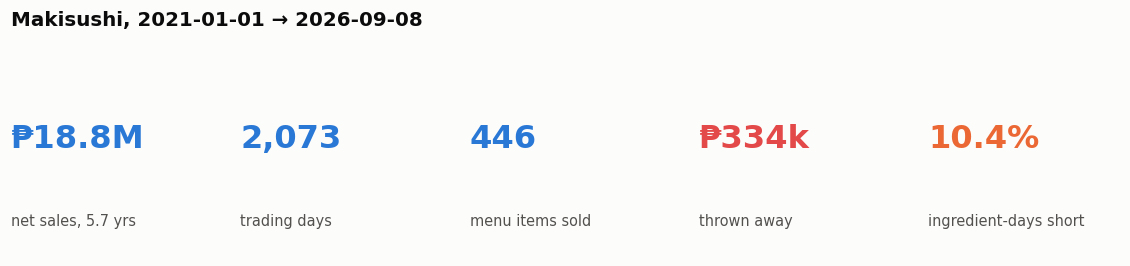

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(13, 2.2))
tiles = [
    (f"₱{sales.net_sales.sum()/1e6:.1f}M", "net sales, 5.7 yrs", S1),
    (f"{sales.date.nunique():,}", "trading days", S1),
    (f"{sales.item_id.nunique():,}", "menu items sold", S1),
    (f"₱{waste.waste_value_php.sum()/1e3:.0f}k", "thrown away", S8),
    (f"{inventory.stockout_flag.mean():.1%}", "ingredient-days short", S2),
]
for ax, (big, label, colour) in zip(axes, tiles):
    ax.axis("off")
    ax.text(0, 0.62, big, fontsize=21, fontweight="bold", color=colour, va="center")
    ax.text(0, 0.18, label, fontsize=9.5, color=INK2, va="center")
fig.suptitle("Makisushi, 2021-01-01 → 2026-09-08", x=0.125, y=1.12,
             ha="left", fontsize=13, fontweight="semibold")
plt.show()

## 2. Sales

### 2.1 Does the seam show?

The generated backfill has to hand over to the real records without a visible
step. The line below is a 28-day rolling mean so the trend is readable; the
dashed marker is the handover on 2025-12-01.

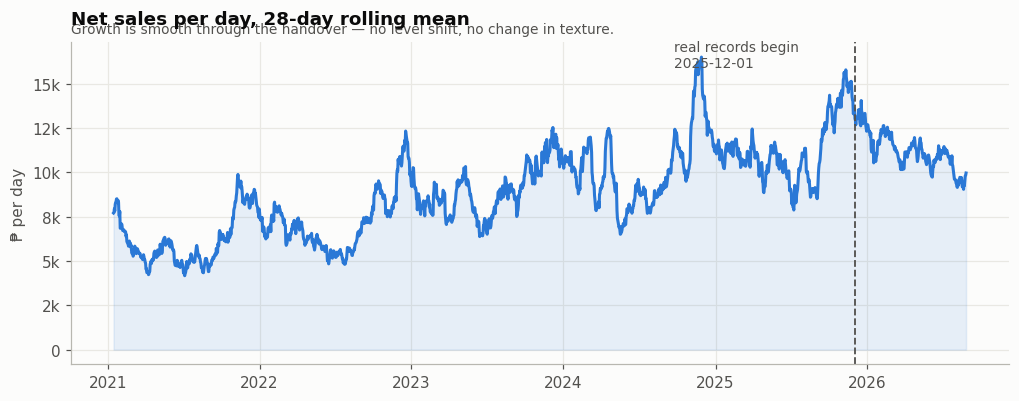

In [7]:
daily = (sales.groupby("date", as_index=False)
         .agg(net=("net_sales", "sum"), units=("quantity_sold", "sum"),
              lines=("sale_id", "count")))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily.date, daily.net.rolling(28, center=True).mean(), color=S1)
ax.fill_between(daily.date, 0, daily.net.rolling(28, center=True).mean(),
                color=S1, alpha=0.10)
ax.axvline(SEAM, color=INK2, ls="--", lw=1.2)
ax.annotate("real records begin\n2025-12-01", xy=(SEAM, ax.get_ylim()[1]*0.92),
            xytext=(-118, 0), textcoords="offset points", fontsize=9, color=INK2)
peso(ax)
finish(ax, "Net sales per day, 28-day rolling mean",
       "Growth is smooth through the handover — no level shift, no change in texture.",
       ylab="₱ per day")
plt.show()

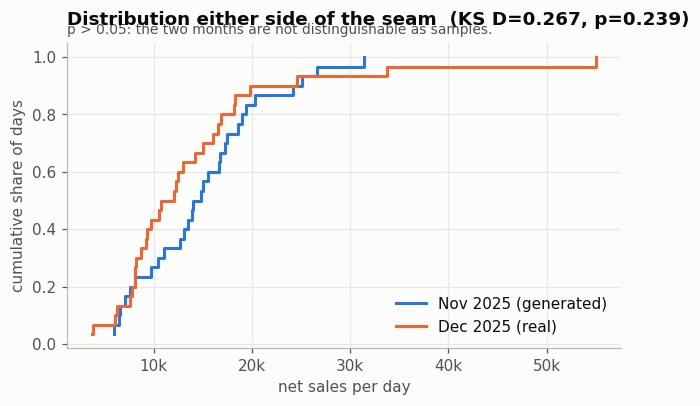

mean ₱/day  generated Nov: 14817   real Dec: 13877


In [8]:
# the formal check: 30 days either side of the seam, two-sample KS
from scipy import stats

pre  = daily.loc[(daily.date >= SEAM - pd.Timedelta(days=30)) & (daily.date < SEAM), "net"]
post = daily.loc[(daily.date >= SEAM) & (daily.date < SEAM + pd.Timedelta(days=31)), "net"]
D, p = stats.ks_2samp(pre, post)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for s, lab, colour in [(pre, "Nov 2025 (generated)", S1), (post, "Dec 2025 (real)", S2)]:
    x = np.sort(s)
    ax.step(x, np.arange(1, len(x)+1)/len(x), where="post", color=colour, label=lab)
peso(ax, "x")
ax.legend(loc="lower right")
finish(ax, f"Distribution either side of the seam  (KS D={D:.3f}, p={p:.3f})",
       "p > 0.05: the two months are not distinguishable as samples.",
       xlab="net sales per day", ylab="cumulative share of days")
plt.show()
print("mean ₱/day  generated Nov: %,.0f   real Dec: %,.0f".replace(",", "")
      % (pre.mean(), post.mean()))

### 2.2 The week has a shape — and it is not the one you'd guess

The intuition for restaurants is "weekends are busiest." This is an office
district at lunchtime, and the data says the opposite: **Wednesday peaks, Sunday
and Monday trough.** Both halves of the dataset agree, which is the real test —
the weekly shape was measured from the owner's records and reproduced in the
backfill.

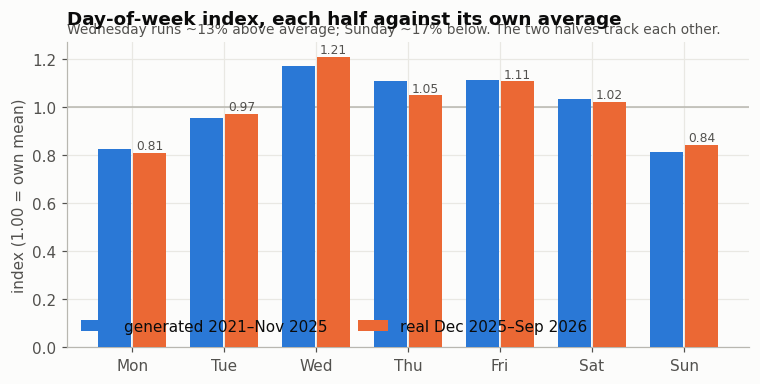

In [9]:
dow_lbl = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
per_day = sales.groupby(["date", "dow", "is_real"], as_index=False).net_sales.sum()
prof = (per_day.groupby(["is_real", "dow"]).net_sales.mean().unstack(0))
prof.columns = ["generated 2021–Nov 2025", "real Dec 2025–Sep 2026"]
idx = (prof / prof.mean()).round(3)          # index to each half's own mean

fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.38
for i, (col, colour) in enumerate(zip(idx.columns, [S1, S2])):
    ax.bar(np.arange(7) + (i - 0.5) * w, idx[col], width=w - 0.02,
           color=colour, label=col, zorder=3)
ax.axhline(1.0, color=MUTED, lw=1)
for i, v in enumerate(idx.iloc[:, 1]):
    ax.text(i + 0.5*w, v + 0.015, f"{v:.2f}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(range(7), dow_lbl)
ax.legend(loc="lower left", ncols=2)
finish(ax, "Day-of-week index, each half against its own average",
       "Wednesday runs ~13% above average; Sunday ~17% below. The two halves track each other.",
       ylab="index (1.00 = own mean)")
plt.show()

### 2.3 Seasonality: ber-months up, rainy quarter down

Philippine retail has a pronounced Q4 — the "ber-months" plus 13th-month pay —
and a slow Q3 when classes resume and the rains set in.

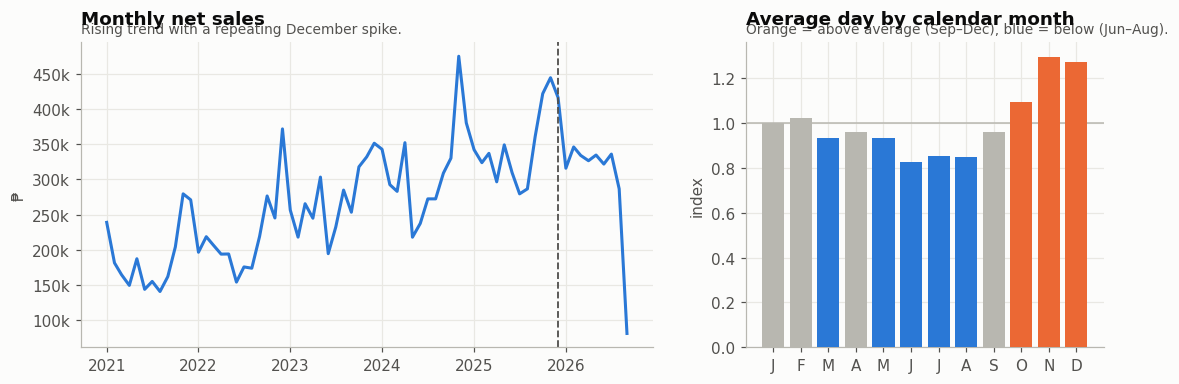

In [10]:
monthly = (sales.assign(m=sales.date.dt.to_period("M"))
           .groupby("m").net_sales.sum().to_timestamp())
by_month = sales.groupby("month").net_sales.sum() / sales.groupby("month").date.nunique()
by_month = by_month / by_month.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(monthly.index, monthly.values, color=S1)
ax.axvline(SEAM, color=INK2, ls="--", lw=1.2)
peso(ax)
finish(ax, "Monthly net sales", "Rising trend with a repeating December spike.", ylab="₱")

ax = axes[1]
cols = [S2 if v >= 1.05 else (S1 if v <= 0.95 else MUTED) for v in by_month]
ax.bar(range(1, 13), by_month.values, color=cols, zorder=3)
ax.axhline(1, color=MUTED, lw=1)
ax.set_xticks(range(1, 13), ["J","F","M","A","M","J","J","A","S","O","N","D"])
finish(ax, "Average day by calendar month",
       "Orange = above average (Sep–Dec), blue = below (Jun–Aug).", ylab="index")
plt.show()

### 2.4 A few dishes carry the restaurant

Menu breadth is 446 items, but demand is heavily concentrated — which matters
enormously downstream: the handful of dishes on the left of this curve are what
actually drives ingredient consumption.

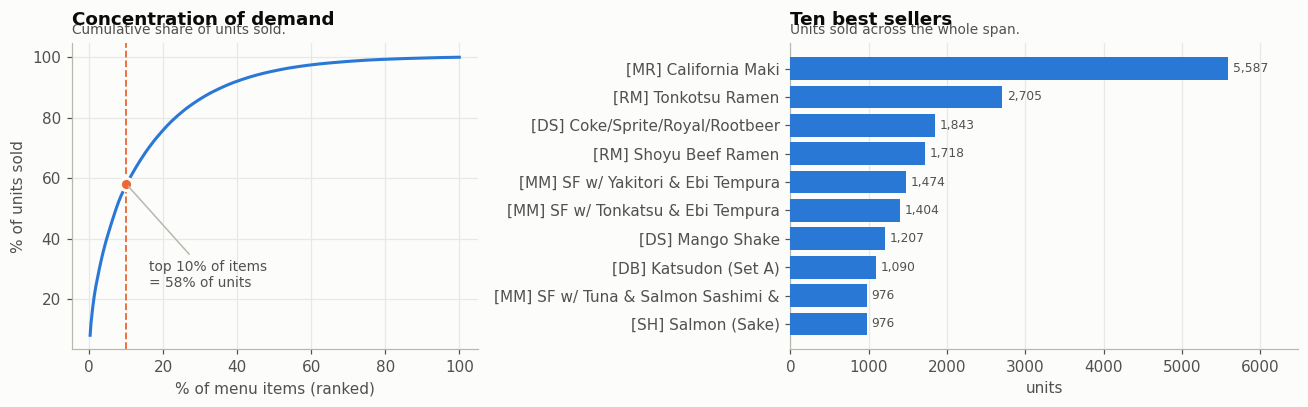

In [11]:
by_item = (sales.groupby("item_id").quantity_sold.sum()
           .sort_values(ascending=False))
share = by_item.cumsum() / by_item.sum()
top10 = share.iloc[int(len(share)*0.10)]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ax.plot(np.arange(1, len(share)+1) / len(share) * 100, share.values * 100, color=S1)
ax.axvline(10, color=S2, ls="--", lw=1.2)
ax.plot([10], [top10*100], "o", ms=8, color=S2, mec="#fcfcfb", mew=2)
ax.annotate(f"top 10% of items\n= {top10:.0%} of units", xy=(10, top10*100),
            xytext=(16, top10*100 - 34), fontsize=9, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED))
finish(ax, "Concentration of demand", "Cumulative share of units sold.",
       xlab="% of menu items (ranked)", ylab="% of units sold")

ax = axes[1]
names = menu.set_index("item_id").item_name
t = by_item.head(10)[::-1]
ax.barh([names.get(i, str(i))[:34] for i in t.index], t.values, color=S1, zorder=3)
ax.bar_label(ax.containers[0], padding=3, fontsize=8, color=INK2,
             fmt=lambda v: f"{v:,.0f}")
ax.grid(axis="y", visible=False)
ax.margins(x=0.16)
finish(ax, "Ten best sellers", "Units sold across the whole span.", xlab="units")
plt.tight_layout()
plt.show()

### 2.5 The messy parts are deliberate

The owner's export has quirks the generator reproduces rather than scrubs,
because a DSS that only works on clean data will not survive contact with the
POS. Quantity is almost always 1; a quarter of lines carry a discount; management
comps land at zero net; and `cost_of_goods` is empty on every single row — which
is why gross profit cannot be computed from this table at all.

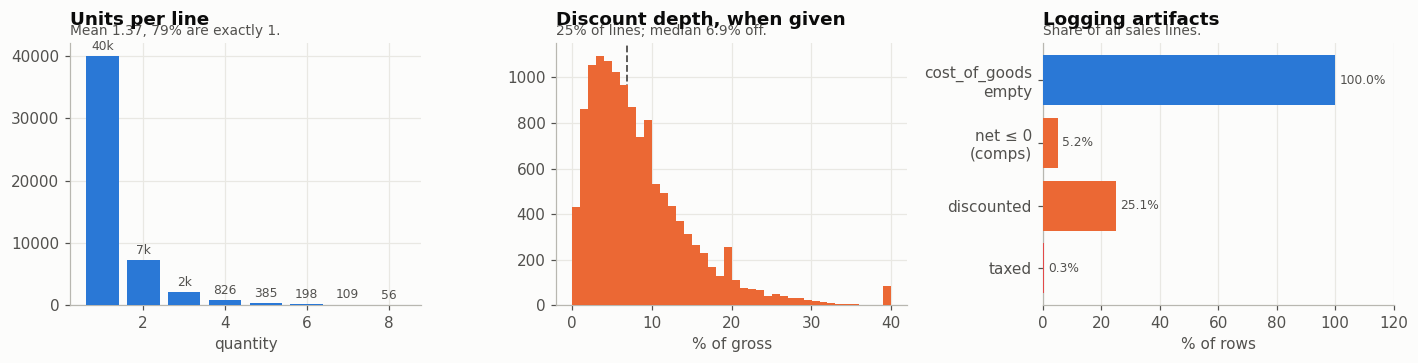

duplicate (item, date) pairs: 163
category labels in use:       34 — including near-duplicate spellings, e.g. ['DON BURI (PORK)', 'DON BURI (BEEF)', 'DON BURI (CHICKEN)']


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

ax = axes[0]
q = sales.quantity_sold.value_counts().sort_index().head(8)
ax.bar(q.index, q.values, color=S1, zorder=3)
ax.bar_label(ax.containers[0], fmt=lambda v: f"{v/1000:.0f}k" if v > 999 else f"{v:.0f}",
             padding=2, fontsize=8, color=INK2)
finish(ax, "Units per line", f"Mean {sales.quantity_sold.mean():.2f}, "
       f"{(sales.quantity_sold==1).mean():.0%} are exactly 1.", xlab="quantity")

ax = axes[1]
d = sales.loc[sales.discount > 0]
pct = (d.discount / d.gross_sales.replace(0, np.nan) * 100).dropna()
ax.hist(pct.clip(0, 40), bins=40, color=S2, zorder=3)
ax.axvline(pct.median(), color=INK2, ls="--", lw=1.2)
finish(ax, "Discount depth, when given",
       f"{(sales.discount>0).mean():.0%} of lines; median {pct.median():.1f}% off.",
       xlab="% of gross")

ax = axes[2]
qual = pd.Series({
    "cost_of_goods\nempty": sales.cost_of_goods.isna().mean(),
    "net ≤ 0\n(comps)": (sales.net_sales <= 0).mean(),
    "discounted": (sales.discount > 0).mean(),
    "taxed": (sales.taxes > 0).mean(),
})
ax.barh(qual.index[::-1], qual.values[::-1]*100, color=[S1, S2, S2, S8][::-1], zorder=3)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8, color=INK2)
ax.grid(axis="y", visible=False)
ax.margins(x=0.2)
finish(ax, "Logging artifacts", "Share of all sales lines.", xlab="% of rows")
plt.tight_layout()
plt.show()

print("duplicate (item, date) pairs:", int(sales.duplicated(['date_id','item_id']).sum()))
print("category labels in use:      ", sales.category.nunique(),
      "— including near-duplicate spellings, e.g.",
      [c for c in sales.category.unique() if "DONBURI" in str(c) or "DON BURI" in str(c)][:3])

### 2.6 Channel mix moved over time

Delivery was a large share of trade in 2021 and decayed as dine-in came back —
a slow structural drift that any model fitted across the full span has to cope
with.

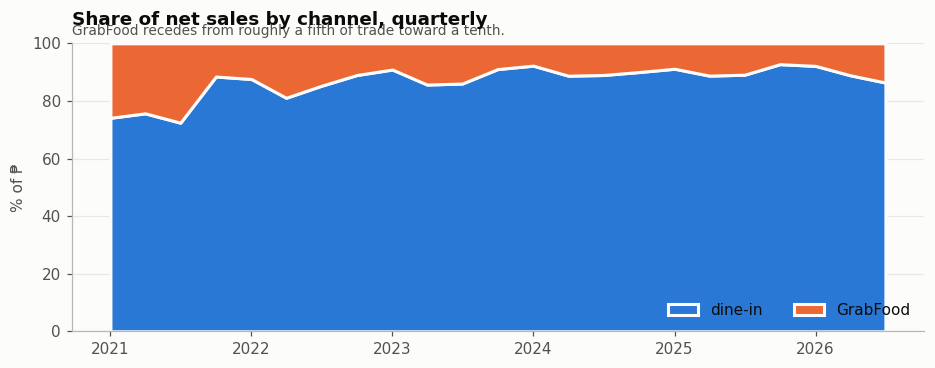

In [13]:
ch = (sales.assign(q=sales.date.dt.to_period("Q"))
      .pivot_table(index="q", columns="channel", values="net_sales", aggfunc="sum")
      .fillna(0))
ch = (ch.div(ch.sum(axis=1), axis=0) * 100).to_timestamp()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.stackplot(ch.index, ch["dine-in"], ch["GrabFood"],
             colors=[S1, S2], labels=["dine-in", "GrabFood"], edgecolor="#fcfcfb", lw=2)
ax.set_ylim(0, 100)
ax.legend(loc="lower right", ncols=2)
finish(ax, "Share of net sales by channel, quarterly",
       "GrabFood recedes from roughly a fifth of trade toward a tenth.", ylab="% of ₱")
plt.show()

## 3. The central claim: sales and inventory are one system

Everything so far was about sales alone. This section tests the thing the whole
capstone rests on — that stock movements are *caused* by dishes sold, through the
recipes:

```
dish sold  ──recipes──▶  ingredients drawn from stock  ──▶  stock falls
    │                                                          │
    │                                        low stock ⇒ order from supplier
    │                                                          │
    └──────────── stock expires before use ⇒ waste ◀───────────┘
```

If that chain is real, then recomputing ingredient demand *from the sales table
alone* should reproduce what the inventory ledger says was consumed. That is a
falsifiable prediction, so let's check it.

In [14]:
# Step 1 — explode sales through the recipes into ingredient demand.
# qty_base is the owner's recipe quantity normalised to a base unit (g or pieces).
link = (sales[["date", "item_id", "quantity_sold"]]
        .merge(recipes[["item_id", "ingredient_id", "qty_base"]], on="item_id")
        .assign(demand=lambda d: d.quantity_sold * d.qty_base)
        .groupby(["date", "ingredient_id"], as_index=False).demand.sum())

# Step 2 — line it up against what the ledger recorded.
chk = (inventory[["date", "ingredient_id", "qty_consumed", "stockout_flag"]]
       .merge(link, on=["date", "ingredient_id"], how="left")
       .fillna({"demand": 0.0}))

served = chk.loc[~chk.stockout_flag]
r_all    = chk.demand.corr(chk.qty_consumed)
r_served = served.demand.corr(served.qty_consumed)
print(f"correlation, all ingredient-days      : r = {r_all:.4f}")
print(f"correlation, days that were fully stocked: r = {r_served:.6f}")
print(f"largest gap on a fully-stocked day    : {(served.demand - served.qty_consumed).abs().max():.6f}")

correlation, all ingredient-days      : r = 0.7375
correlation, days that were fully stocked: r = 1.000000
largest gap on a fully-stocked day    : 0.000000


**On any day the kitchen was in stock, consumption equals recipe-implied demand
to floating-point precision.** The ledger is not an independent random table that
happens to correlate — it is the arithmetic consequence of the sales table.

Where the two *do* come apart is exactly where they should: days the ingredient
ran out. That gap is the lost sale.

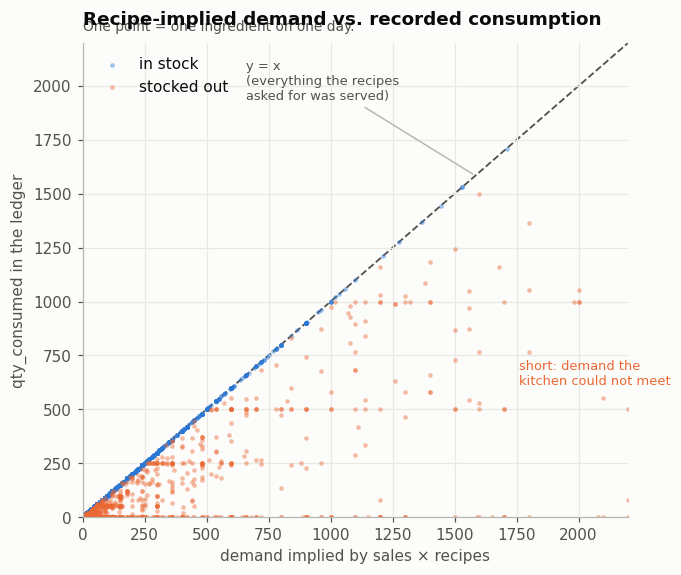

In [15]:
samp = chk[chk.demand > 0].sample(6000, random_state=0)
fig, ax = plt.subplots(figsize=(6.4, 5.6))
lim = np.percentile(samp.demand, 99.5)
for flag, colour, lab in [(False, S1, "in stock"), (True, S2, "stocked out")]:
    s = samp[samp.stockout_flag == flag]
    ax.scatter(s.demand, s.qty_consumed, s=9, alpha=0.45, color=colour,
               label=lab, linewidths=0)
ax.plot([0, lim], [0, lim], color=INK2, lw=1.2, ls="--", zorder=0)
ax.annotate("y = x\n(everything the recipes\nasked for was served)",
            xy=(lim*0.72, lim*0.72), xytext=(lim*0.30, lim*0.88),
            fontsize=8.5, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.annotate("short: demand the\nkitchen could not meet", xy=(lim*0.8, lim*0.28),
            fontsize=8.5, color=S2)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.legend(loc="upper left")
finish(ax, "Recipe-implied demand vs. recorded consumption",
       "One point = one ingredient on one day.",
       xlab="demand implied by sales × recipes", ylab="qty_consumed in the ledger")
plt.show()

### 3.2 Watching one ingredient's ledger tick over

The correlation proves the link in aggregate. This is the same thing at
human scale: eight weeks of the single busiest ingredient, with deliveries
arriving, stock drawing down, and the ledger identity
`closing = opening + received − consumed − wasted` holding on every line.

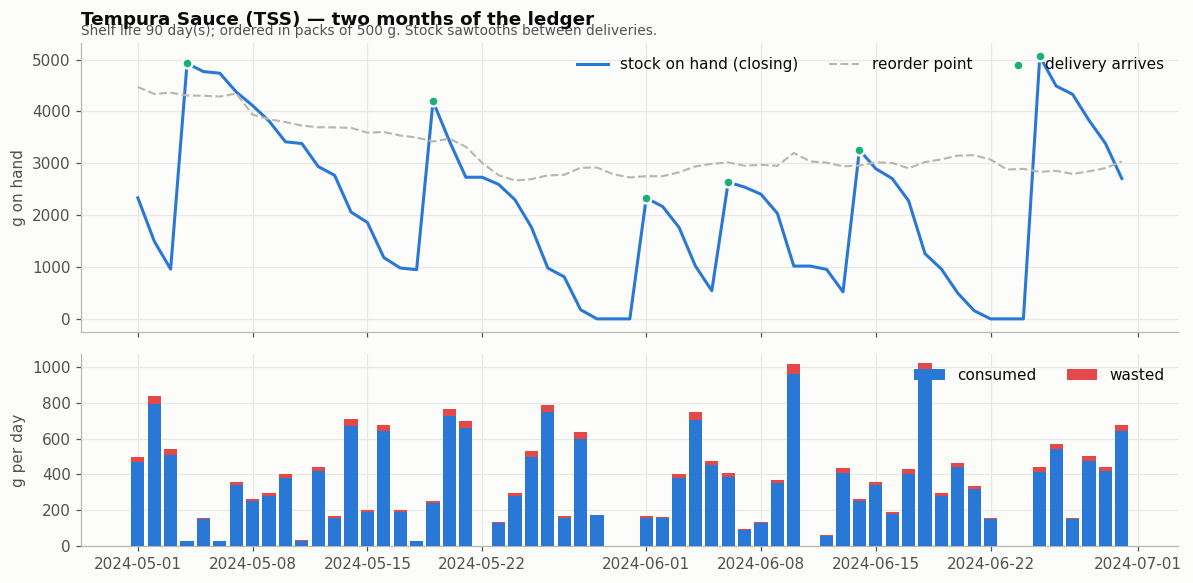

worst ledger imbalance in this window: 0.000100000


In [16]:
star = int(inventory.groupby("ingredient_id").qty_consumed.sum().idxmax())
nm = ingr.set_index("ingredient_id").loc[star]
win = inventory[(inventory.ingredient_id == star) &
                inventory.date.between("2024-05-01", "2024-06-30")].copy()

fig, axes = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True,
                         gridspec_kw={"height_ratios": [1.5, 1]})
ax = axes[0]
ax.plot(win.date, win.closing_stock, color=S1, label="stock on hand (closing)")
ax.plot(win.date, win.reorder_level, color=MUTED, lw=1.4, ls="--", label="reorder point")
rec = win[win.qty_received > 0]
ax.scatter(rec.date, rec.closing_stock, s=42, color=S3, zorder=5,
           label="delivery arrives", ec="#fcfcfb", lw=1.5)
ax.legend(loc="upper right", ncols=3)
finish(ax, f"{nm.ingredient_name} ({nm.ingredient_code}) — two months of the ledger",
       f"Shelf life {int(nm.shelf_life_days)} day(s); ordered in packs of "
       f"{nm.pack_size:.0f} {nm.uom}. Stock sawtooths between deliveries.",
       ylab=f"{nm.uom} on hand")

ax = axes[1]
ax.bar(win.date, win.qty_consumed, color=S1, label="consumed", zorder=3)
ax.bar(win.date, win.qty_wasted, bottom=win.qty_consumed, color=S8,
       label="wasted", zorder=3)
ax.legend(loc="upper right", ncols=2)
finish(ax, None, None, ylab=f"{nm.uom} per day")
plt.tight_layout()
plt.show()

ident = (win.opening_stock + win.qty_received - win.qty_consumed
         - win.qty_wasted - win.closing_stock).abs().max()
print(f"worst ledger imbalance in this window: {ident:.9f}")

### 3.3 Orders follow demand, with a delay

If the chain runs the way it's drawn, a busy stretch should show up first in
consumption, then in deliveries a lead time later. Cross-correlating the two
daily series recovers that delay without being told it.

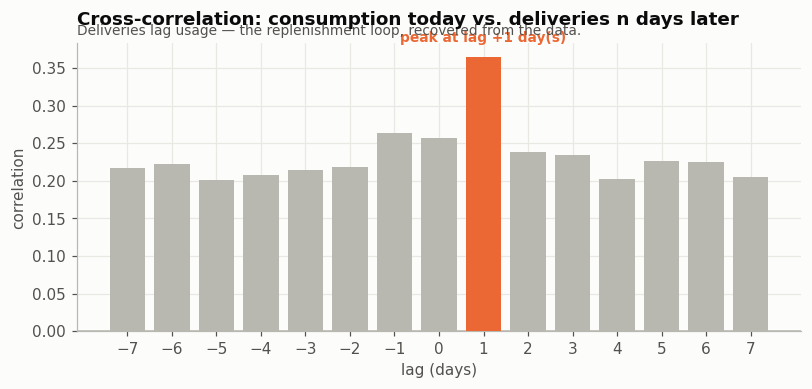

In [17]:
d_cons = inventory.groupby("date").qty_consumed.sum()
d_recv = inventory.groupby("date").qty_received.sum()
a = (d_cons - d_cons.mean()) / d_cons.std()
b = (d_recv - d_recv.mean()) / d_recv.std()
lags = range(-7, 8)
ccf = [a.corr(b.shift(-L)) for L in lags]
best = list(lags)[int(np.argmax(ccf))]

fig, ax = plt.subplots(figsize=(8.5, 3.4))
cols = [S2 if L == best else MUTED for L in lags]
ax.bar(list(lags), ccf, color=cols, zorder=3)
ax.axhline(0, color=MUTED, lw=1)
ax.annotate(f"peak at lag {best:+d} day(s)", xy=(best, max(ccf)),
            xytext=(0, 10), textcoords="offset points", ha="center",
            fontsize=9, color=S2, fontweight="semibold")
ax.set_xticks(list(lags))
finish(ax, "Cross-correlation: consumption today vs. deliveries n days later",
       "Deliveries lag usage — the replenishment loop, recovered from the data.",
       xlab="lag (days)", ylab="correlation")
plt.show()

### 3.4 …and waste follows over-ordering — but only where it can

The last link in the chain. Group ingredient-days by how much stock was sitting
there relative to that ingredient's own recent usage, and split by whether the
ingredient is perishable. The contrast is the mechanism: **carrying more stock
only turns into waste if the thing can spoil.** Non-perishables sit flat no
matter how deep the pile gets; perishables climb steeply.

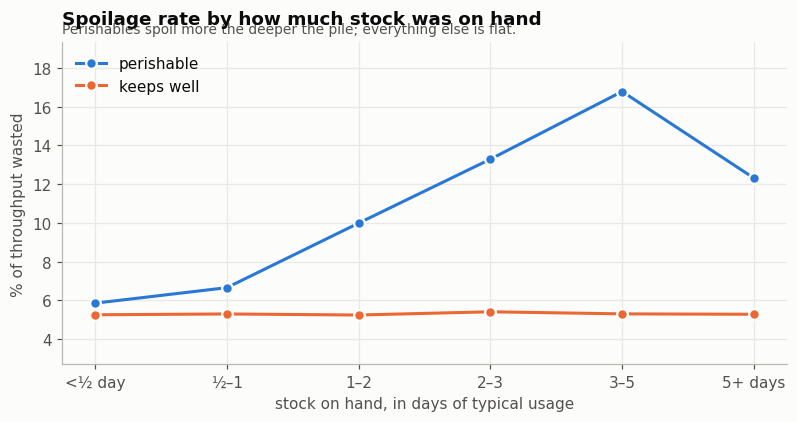

The dip in the rightmost perishable point is a composition effect, not a reversal:
only 29% of that bucket is 1–2 day stock, against 70% of the others.
Nothing survives five days of cover unless it keeps for more than two.


In [18]:
w = inventory.copy()
w["perishable"] = w.ingredient_id.map(ingr.set_index("ingredient_id").is_perishable)
w["shelf_life_days"] = w.ingredient_id.map(ingr.set_index("ingredient_id").shelf_life_days)
w["mu"] = w.groupby("ingredient_id").qty_consumed.transform(
    lambda s: s.rolling(28, min_periods=7).mean())
w = w[(w.mu > 0) & (w.closing_stock >= 0)]
w["cover"] = w.closing_stock / w.mu                      # days of stock on hand
w["bucket"] = pd.cut(w.cover, [0, .5, 1, 2, 3, 5, np.inf],
                     labels=["<½ day", "½–1", "1–2", "2–3", "3–5", "5+ days"])


def waste_rate(d):
    return 100 * d.qty_wasted.sum() / max(d.qty_consumed.sum() + d.qty_wasted.sum(), 1)


g = (w.groupby(["perishable", "bucket"], observed=True)
     .apply(waste_rate).unstack(0))
n = w.groupby(["perishable", "bucket"], observed=True).size().unstack(0)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(g))
ax.plot(x, g[True], color=S1, marker="o", ms=7, mec="#fcfcfb", mew=1.5,
        label="perishable")
ax.plot(x, g[False], color=S2, marker="o", ms=7, mec="#fcfcfb", mew=1.5,
        label="keeps well")
ax.set_xticks(x, g.index.astype(str))
ax.legend(loc="upper left")
ax.margins(y=0.22)
finish(ax, "Spoilage rate by how much stock was on hand",
       "Perishables spoil more the deeper the pile; everything else is flat.",
       xlab="stock on hand, in days of typical usage", ylab="% of throughput wasted")
plt.show()

deep = w[(w.perishable) & (w.bucket == "5+ days")]
rest = w[(w.perishable) & (w.bucket != "5+ days")]
print("The dip in the rightmost perishable point is a composition effect, not a "
      "reversal:\nonly %.0f%% of that bucket is 1–2 day stock, against %.0f%% of "
      "the others.\nNothing survives five days of cover unless it keeps for more "
      "than two." % ((deep.shelf_life_days <= 2).mean()*100,
                     (rest.shelf_life_days <= 2).mean()*100))

## 4. Where the money leaks

### 4.1 Waste by reason, by ingredient, over time

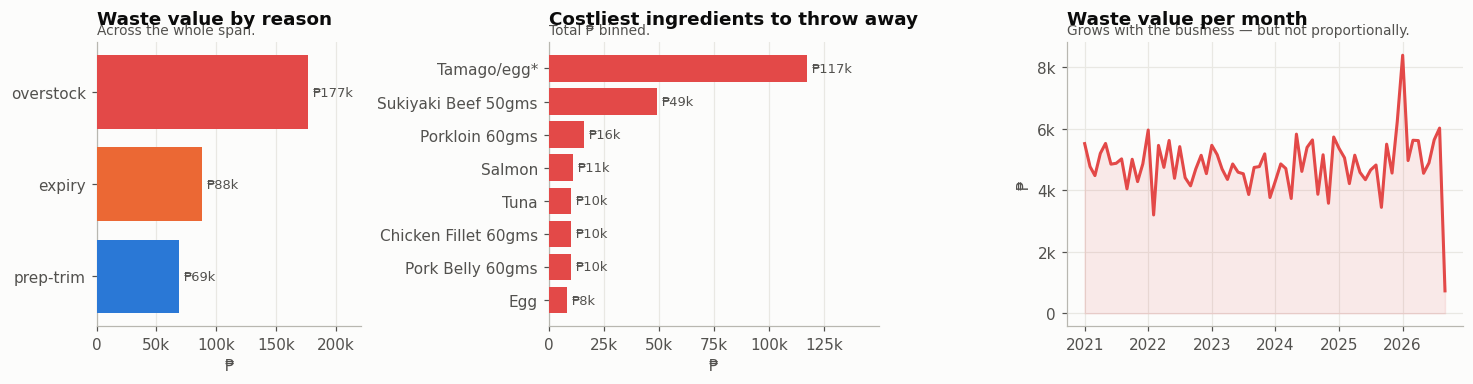

waste as a share of everything bought: 11.5%


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6),
                         gridspec_kw={"width_ratios": [1, 1.25, 1.5]})

ax = axes[0]
by_reason = waste.groupby("waste_reason").waste_value_php.sum().sort_values()
ax.barh(by_reason.index, by_reason.values, zorder=3,
        color=[S1, S2, S8][:len(by_reason)])
ax.bar_label(ax.containers[0], fmt=lambda v: f"₱{v/1000:.0f}k", padding=3,
             fontsize=8.5, color=INK2)
ax.grid(axis="y", visible=False); ax.margins(x=0.25)
peso(ax, "x")
finish(ax, "Waste value by reason", "Across the whole span.", xlab="₱")

ax = axes[1]
nm = ingr.set_index("ingredient_id").ingredient_name
tw = waste.groupby("ingredient_id").waste_value_php.sum().nlargest(8)[::-1]
ax.barh([str(nm.get(i, i))[:26] for i in tw.index], tw.values, color=S8, zorder=3)
ax.bar_label(ax.containers[0], fmt=lambda v: f"₱{v/1000:.0f}k", padding=3,
             fontsize=8.5, color=INK2)
ax.grid(axis="y", visible=False); ax.margins(x=0.28)
peso(ax, "x")
finish(ax, "Costliest ingredients to throw away", "Total ₱ binned.", xlab="₱")

ax = axes[2]
mw = waste.groupby(waste.date.dt.to_period("M")).waste_value_php.sum().to_timestamp()
ax.plot(mw.index, mw.values, color=S8)
ax.fill_between(mw.index, 0, mw.values, color=S8, alpha=0.10)
peso(ax)
finish(ax, "Waste value per month", "Grows with the business — but not proportionally.",
       ylab="₱")
plt.tight_layout()
plt.show()

thr = inventory.qty_consumed.sum() + inventory.qty_wasted.sum()
print(f"waste as a share of everything bought: {inventory.qty_wasted.sum()/thr:.1%}")

### 4.2 Shelf life is destiny

Ingredients that keep for a day or two are thrown away at many times the rate of
anything that keeps for a month. This is the whole problem in one chart: the
menu's signature items are built on its most fragile inputs.

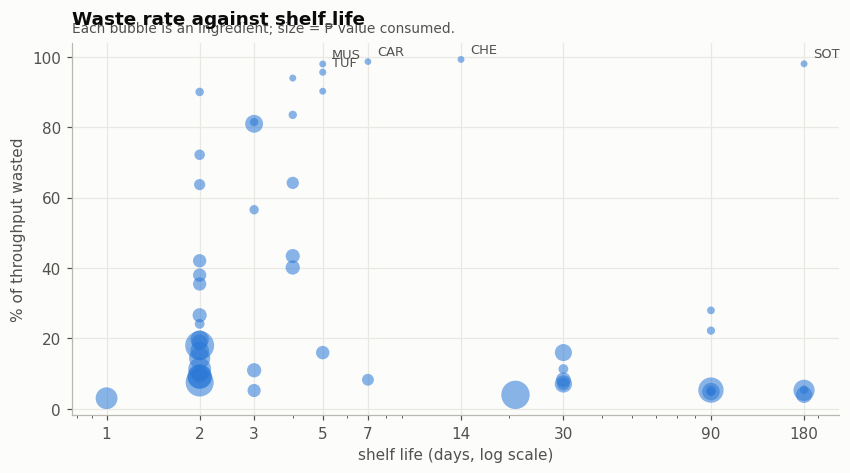

In [20]:
per_ing = (inventory.groupby("ingredient_id")
           .agg(cons=("qty_consumed", "sum"), wst=("qty_wasted", "sum"),
                stockout=("stockout_flag", "mean"))
           .join(ingr.set_index("ingredient_id")[
               ["ingredient_code", "ingredient_name", "shelf_life_days",
                "is_perishable", "unit_cost"]]))
per_ing = per_ing[per_ing.cons > 0]
per_ing["waste_pct"] = per_ing.wst / (per_ing.cons + per_ing.wst) * 100
per_ing["value"] = per_ing.cons * per_ing.unit_cost

fig, ax = plt.subplots(figsize=(9, 4.4))
sizes = 18 + 340 * (per_ing.value / per_ing.value.max()) ** 0.5
ax.scatter(per_ing.shelf_life_days, per_ing.waste_pct, s=sizes, alpha=0.55,
           color=S1, linewidths=0)
ax.set_xscale("log")
ax.set_xticks([1, 2, 3, 5, 7, 14, 30, 90, 180],
              ["1", "2", "3", "5", "7", "14", "30", "90", "180"])
for i, r in per_ing.nlargest(5, "waste_pct").iterrows():
    ax.annotate(r.ingredient_code, (r.shelf_life_days, r.waste_pct),
                xytext=(6, 4), textcoords="offset points", fontsize=8.5, color=INK2)
finish(ax, "Waste rate against shelf life",
       "Each bubble is an ingredient; size = ₱ value consumed.",
       xlab="shelf life (days, log scale)", ylab="% of throughput wasted")
plt.show()

### 4.3 The other side of the ledger: running out

Waste and stockouts are the two ways to be wrong, and they pull in opposite
directions. Ordering less would cut the waste above — and push this up.

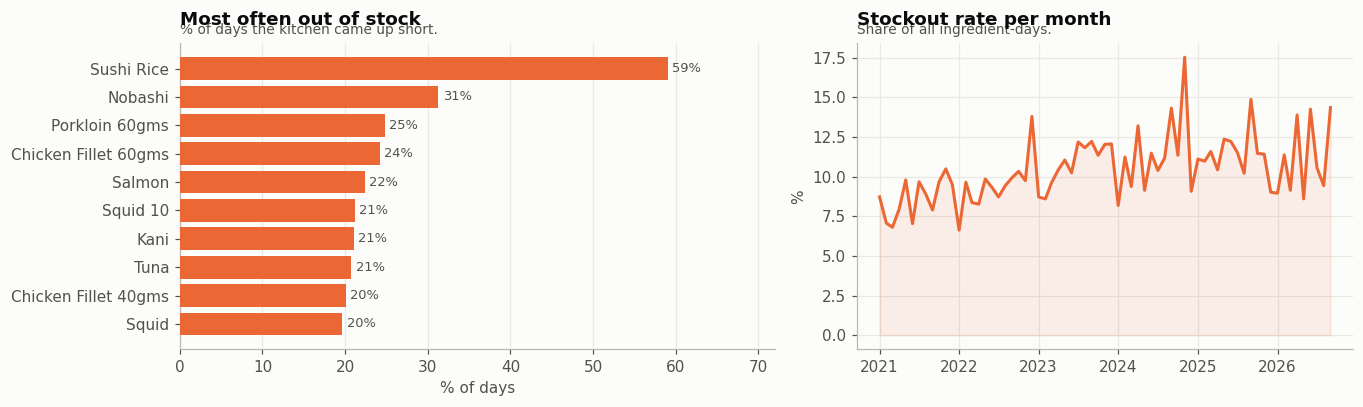

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8),
                         gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
so = per_ing.nlargest(10, "stockout").sort_values("stockout")
ax.barh([str(s)[:26] for s in so.ingredient_name], so.stockout*100, color=S2, zorder=3)
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3, fontsize=8.5, color=INK2)
ax.grid(axis="y", visible=False); ax.margins(x=0.22)
finish(ax, "Most often out of stock", "% of days the kitchen came up short.",
       xlab="% of days")

ax = axes[1]
m = (inventory.groupby(inventory.date.dt.to_period("M")).stockout_flag.mean()*100).to_timestamp()
ax.plot(m.index, m.values, color=S2)
ax.fill_between(m.index, 0, m.values, color=S2, alpha=0.10)
finish(ax, "Stockout rate per month", "Share of all ingredient-days.", ylab="%")
plt.tight_layout()
plt.show()

### 4.4 How long things sit before they're binned

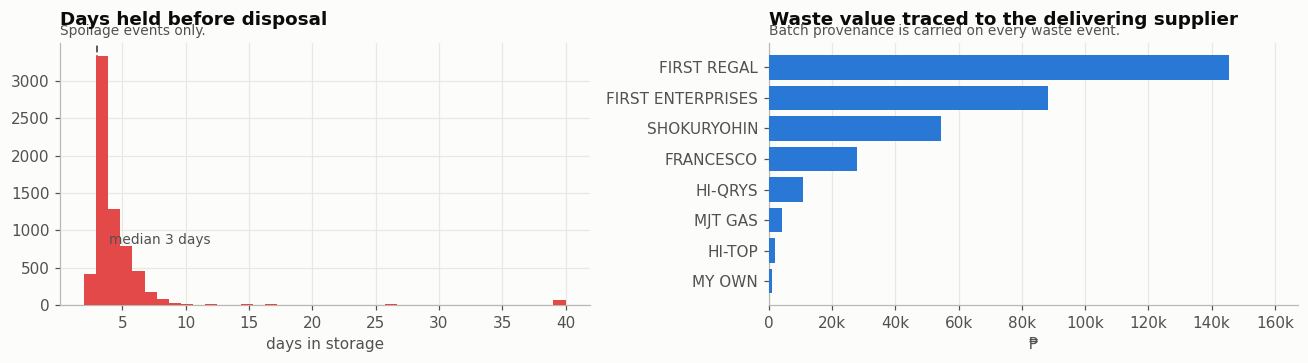

In [22]:
sp = waste[waste.waste_reason.isin(["expiry", "overstock"])]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))

ax = axes[0]
ax.hist(sp.days_held.clip(0, 40), bins=40, color=S8, zorder=3)
ax.axvline(sp.days_held.median(), color=INK2, ls="--", lw=1.2)
ax.annotate(f"median {sp.days_held.median():.0f} days", (sp.days_held.median(), 0),
            xytext=(8, 40), textcoords="offset points", fontsize=9, color=INK2)
finish(ax, "Days held before disposal", "Spoilage events only.", xlab="days in storage")

ax = axes[1]
sup_w = (waste.groupby("supplier_id").waste_value_php.sum()
         .rename("waste").to_frame()
         .join(suppliers.set_index("supplier_id")[["supplier_name", "lead_time_mean",
                                                   "fill_rate"]]))
sup_w = sup_w.sort_values("waste")
ax.barh(sup_w.supplier_name, sup_w.waste, color=S1, zorder=3)
peso(ax, "x")
ax.grid(axis="y", visible=False); ax.margins(x=0.15)
finish(ax, "Waste value traced to the delivering supplier",
       "Batch provenance is carried on every waste event.", xlab="₱")
plt.tight_layout()
plt.show()

## 5. Suppliers

Nine real suppliers, each with its own lead time and reliability. These are the
levers the replenishment model will eventually pull against.

In [23]:
sup_view = suppliers.copy()
sup_view["ingredients"] = sup_view.supplier_id.map(
    inventory.groupby("supplier_id").ingredient_id.nunique())
sup_view["₱ ordered"] = sup_view.supplier_id.map(
    inventory.assign(v=inventory.qty_received *
                     inventory.ingredient_id.map(ingr.set_index("ingredient_id").unit_cost))
    .groupby("supplier_id").v.sum()).round(0)
sup_view[["supplier_name", "category_served", "lead_time_mean", "lead_time_sd",
          "fill_rate", "min_order_qty", "delivery_cadence_days",
          "ingredients", "₱ ordered"]].sort_values("₱ ordered", ascending=False)

,supplier_name,category_served,lead_time_mean,lead_time_sd,fill_rate,min_order_qty,delivery_cadence_days,ingredients,₱ ordered
2,FIRST ENTERPRISES,pork/beef,3,1.3,0.956,1,7,8.0,583586.0
0,SHOKURYOHIN,seafood/frozen,2,1.0,0.962,5,3,14.0,544499.0
3,FIRST REGAL,chicken/pork,3,1.3,0.978,1,7,6.0,346537.0
5,HI-QRYS,dry/sauce,5,1.9,0.910,10,7,9.0,180890.0
4,FRANCESCO,veg/produce,1,0.7,0.961,5,2,11.0,118751.0
6,HI-TOP,dry/sauce,5,1.9,0.936,5,7,1.0,68652.0
8,MJT GAS,oil/gas,5,1.9,0.952,2,14,3.0,28613.0
7,MY OWN,misc,4,1.6,0.974,2,7,2.0,6480.0
1,BANRI,seafood,2,1.0,0.969,2,3,NaN,NaN


## 6. What isn't in the files

The generator ran on latent daily states — local area activity, weather severity,
and a manager's ordering bias — that were **deliberately stripped from every
export**. They are not columns anywhere. But they drove several observed
variables at once, so they left correlations behind, and those are exactly the
traps an unwary analysis falls into.

### 6.1 The two ways to be wrong sit at opposite ends of the day

Sort days into quintiles by how busy they were. The two failure modes separate
cleanly and in opposite directions:

- **Quiet days spoil.** A quiet day wastes 27% of everything it touches; a busy
  day, 7%. Stock was bought for a level of trade that didn't arrive.
- **Busy days run short.** Stockouts nearly quadruple from the quietest quintile
  to the busiest.

Note this only shows up in the waste *rate*. Absolute quantity wasted is almost
flat across quintiles (r = −0.07), because busy days push far more volume
through. Reading the raw totals would have hidden the effect entirely.

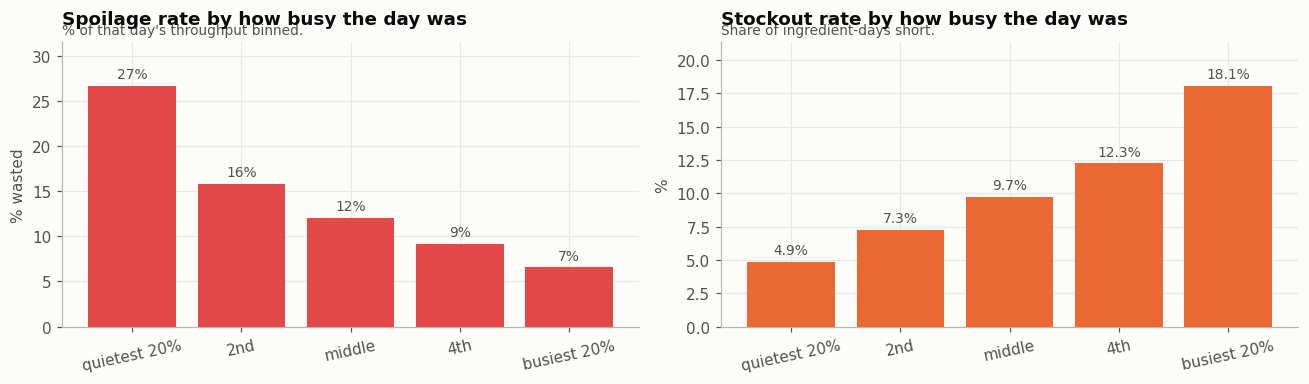

corr(daily net sales, waste RATE)     = -0.487
corr(daily net sales, waste QUANTITY) = -0.070   <- flat
corr(daily net sales, stockout rate)  = +0.730


In [24]:
day = (daily.set_index("date")
       .join(inventory.groupby("date").agg(waste=("qty_wasted", "sum"),
                                           cons=("qty_consumed", "sum"),
                                           short=("stockout_flag", "mean")))
       .dropna())
day["waste_rate"] = day.waste / (day.waste + day.cons) * 100
day["q"] = pd.qcut(day.net, 5, labels=["quietest 20%", "2nd", "middle", "4th", "busiest 20%"])
prof = day.groupby("q", observed=True).agg(
    waste_rate=("waste_rate", "mean"), short=("short", "mean"), waste=("waste", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
ax.bar(prof.index.astype(str), prof.waste_rate, color=S8, zorder=3)
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3, fontsize=9, color=INK2)
ax.margins(y=0.18)
finish(ax, "Spoilage rate by how busy the day was", "% of that day's throughput binned.",
       ylab="% wasted")
ax.tick_params(axis="x", labelrotation=12)

ax = axes[1]
ax.bar(prof.index.astype(str), prof.short*100, color=S2, zorder=3)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=9, color=INK2)
ax.margins(y=0.18)
finish(ax, "Stockout rate by how busy the day was", "Share of ingredient-days short.",
       ylab="%")
ax.tick_params(axis="x", labelrotation=12)
plt.tight_layout()
plt.show()

print(f"corr(daily net sales, waste RATE)     = {day.net.corr(day.waste_rate):+.3f}")
print(f"corr(daily net sales, waste QUANTITY) = {day.net.corr(day.waste):+.3f}   <- flat")
print(f"corr(daily net sales, stockout rate)  = {day.net.corr(day.short):+.3f}")

### 6.1b A link the schema cannot explain

Here is the part that should make you cautious. Take each day's **delivery share**
— how much of the day's money came through GrabFood rather than the dining room.
Nothing connects that number to the stockroom: channel mix lives in the sales
table, spoilage in the waste log, and no key joins them beyond the date.

Yet days with a high delivery share are days with lower sales *and* a higher
spoilage rate, and the pattern repeats in **every one of the six years** — so it
is not the long-run drift in delivery share doing the work. Some unobserved daily
condition is moving the dining room and the walk-in chiller at the same time.

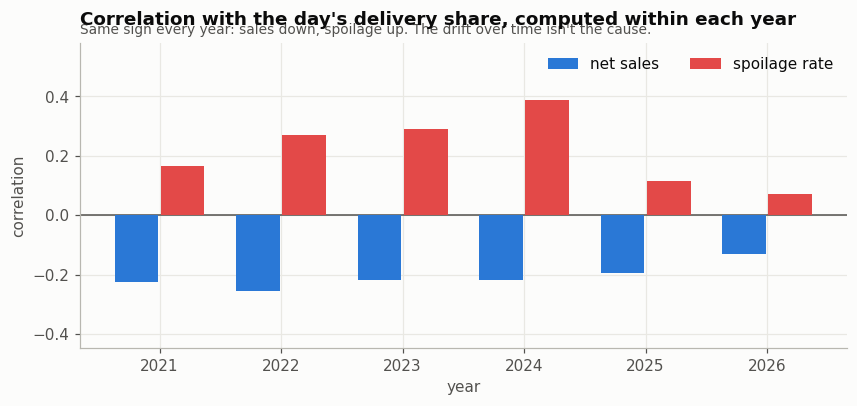

mean within-year corr(delivery share, net sales)     = -0.207
mean within-year corr(delivery share, spoilage rate) = +0.217

No column in these eight files accounts for that. Something outside the schema drives both — and any model that ignores it will attribute the effect to whichever observed variable happens to sit nearby.


In [25]:
gf = (sales[sales.channel == "GrabFood"].groupby("date").net_sales.sum()
      / sales.groupby("date").net_sales.sum())
day["deliv_share"] = gf
day["yr"] = day.index.year

rows = day.groupby("yr").apply(lambda d: pd.Series({
    "net sales": d.deliv_share.corr(d.net),
    "spoilage rate": d.deliv_share.corr(d.waste_rate),
}))

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(rows)); wd = 0.38
ax.bar(x - wd/2, rows["net sales"], wd - 0.02, color=S1, label="net sales", zorder=3)
ax.bar(x + wd/2, rows["spoilage rate"], wd - 0.02, color=S8, label="spoilage rate", zorder=3)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(x, rows.index)
ax.legend(loc="upper right", ncols=2)
ax.margins(y=0.30)
finish(ax, "Correlation with the day's delivery share, computed within each year",
       "Same sign every year: sales down, spoilage up. The drift over time isn't the cause.",
       xlab="year", ylab="correlation")
plt.show()

print(f"mean within-year corr(delivery share, net sales)     = {rows['net sales'].mean():+.3f}")
print(f"mean within-year corr(delivery share, spoilage rate) = {rows['spoilage rate'].mean():+.3f}")
print("\nNo column in these eight files accounts for that. Something outside the "
      "schema drives both — and any model that ignores it will attribute the "
      "effect to whichever observed variable happens to sit nearby.")

### 6.2 The kitchen learned

Compare what was ordered against what was actually used, year by year. Early on
the restaurant buys well over what it needs; the gap narrows steadily. No column
records a manager, an experience level, or a policy change — but the behaviour is
visible in the ratio, and it is the single largest controllable source of waste.

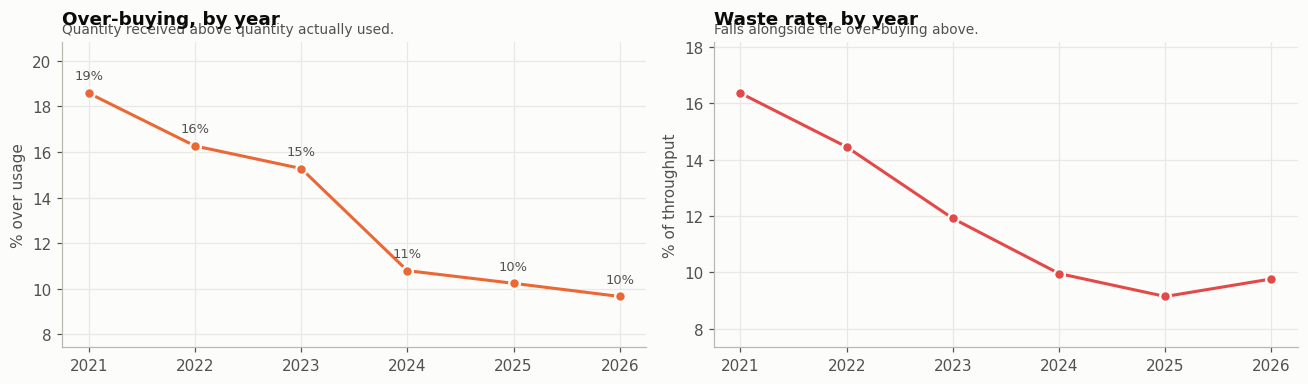

In [26]:
yr = (inventory.groupby("year")
      .agg(ordered=("qty_received", "sum"), used=("qty_consumed", "sum"),
           wasted=("qty_wasted", "sum")))
yr["over"] = (yr.ordered / yr.used - 1) * 100
yr["waste_pct"] = yr.wasted / (yr.used + yr.wasted) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
ax.plot(yr.index, yr.over, color=S2, marker="o", ms=7, mec="#fcfcfb", mew=1.5)
for x, v in yr.over.items():
    ax.annotate(f"{v:.0f}%", (x, v), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=8.5, color=INK2)
ax.margins(y=0.25)
finish(ax, "Over-buying, by year",
       "Quantity received above quantity actually used.", ylab="% over usage")

ax = axes[1]
ax.plot(yr.index, yr.waste_pct, color=S8, marker="o", ms=7, mec="#fcfcfb", mew=1.5)
ax.margins(y=0.25)
finish(ax, "Waste rate, by year", "Falls alongside the over-buying above.",
       ylab="% of throughput")
plt.tight_layout()
plt.show()

### 6.3 Dishes move together more than the calendar explains

Strip out the weekly and seasonal pattern and unrelated dishes still rise and
fall together. Squid tempura has no ingredient in common with a beef bowl, yet
their leftover residuals correlate. Something outside the schema is lifting the
whole restaurant on some days and not others — which means a per-item forecast
that assumes items are independent is leaving information on the table.

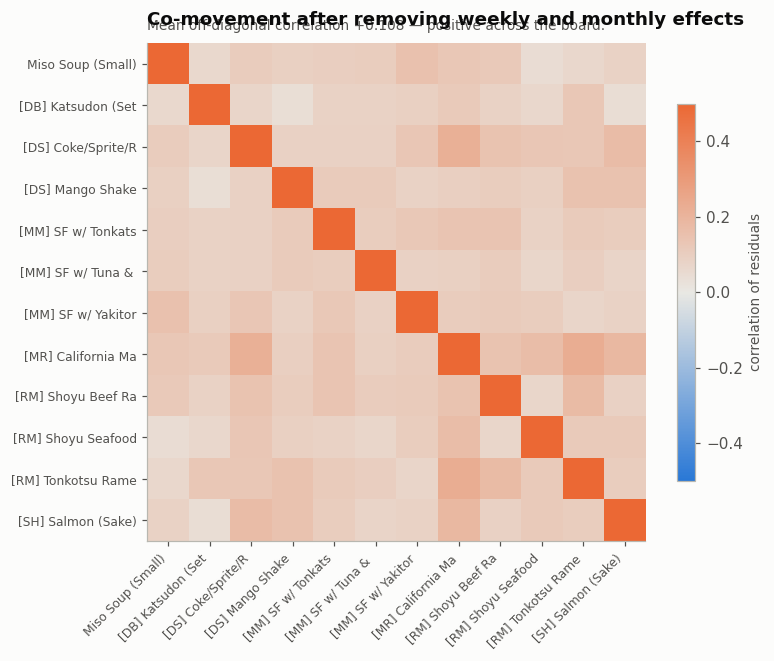

In [27]:
top = by_item.head(12).index
panel = (sales[sales.item_id.isin(top)]
         .pivot_table(index="date", columns="item_id", values="quantity_sold",
                      aggfunc="sum").fillna(0))
# remove day-of-week and month effects, keep what's left
resid = panel.copy()
for c in resid.columns:
    s = resid[c]
    dow_mean = s.groupby(s.index.dayofweek).transform("mean")
    mon_mean = s.groupby(s.index.to_period("M")).transform("mean")
    resid[c] = s - dow_mean - mon_mean + s.mean()

corr = resid.corr()
names = menu.set_index("item_id").item_name
lbl = [str(names.get(i, i))[:18] for i in corr.columns]
off = corr.values[np.triu_indices_from(corr, k=1)]

fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(corr.values, cmap=DIV, vmin=-0.5, vmax=0.5)
ax.set_xticks(range(len(lbl)), lbl, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(lbl)), lbl, fontsize=8)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.75)
cb.set_label("correlation of residuals", fontsize=9, color=INK2)
finish(ax, "Co-movement after removing weekly and monthly effects",
       f"Mean off-diagonal correlation {off.mean():+.3f} — positive across the board.")
plt.tight_layout()
plt.show()

## 7. What this says for the DSS

**The dataset holds together.**  Consumption reconciles to sales through the
recipes exactly on every fully-stocked day (§3.1), the ledger identity never
breaks (§3.2), and the replenishment loop is visible as a lagged correlation
between usage and deliveries (§3.3). Forecasting demand and optimising
replenishment against this data are the same problem, not two.

**The stitch is invisible.**  Generated and real sales are indistinguishable
across the seam (KS p > 0.05), and the Wednesday peak measured in the owner's
records is reproduced in the backfill. Five years of history can be trained on as
one series.

**There is real money on the table.**  Waste runs at roughly a tenth of
everything purchased, concentrated almost entirely in ingredients that keep for a
day or two. Over-buying was the driver, and it shrinks year on year as the
kitchen learns — which puts a ceiling on how much more a purely behavioural fix
can achieve, and makes the case for the model.

**Waste and stockouts trade off.**  They are two sides of one decision (§4.3).
Any replenishment policy has to be scored on both, not on waste alone.

**Mind the confounding.**  Quiet days spoil while busy days run short (§6.1), the
day's delivery share predicts the day's spoilage rate with no schema path between
them (§6.1b), and dishes co-move beyond what the calendar explains (§6.3). The
tempting causal story — "delivery orders are wasteful" — is not what is happening;
an unobserved daily condition is moving both. Whatever model comes next should
carry a day-level effect rather than treating each item and each day as
independent, and should be scored on held-out days rather than held-out rows.

### Where to go next
Forecast bake-off (seasonal naïve → Holt-Winters → SARIMA, scored on WMAPE and
MASE against a seasonal-naïve baseline), then a replenishment LP that minimises
expected spoilage plus stockout cost subject to shelf life, pack sizes, and
supplier lead times. Both want `statsmodels` and `PuLP`, which aren't installed
in this environment yet:

```
pip install statsmodels pulp
```